# 08 · The rubric: a designed zodiac, and no accuracy number anywhere

Notebook 01 measured whether a song's zodiac sign can be learned from scraped playlists.
It can, barely: **11.6% balanced accuracy against an 8.33% chance rate — 1.39×** — with a
control of unrelated playlists given random zodiac labels scoring **0.94×**, confirming
the tiny signal is real rather than a pipeline artefact. Real, and far too small to ship
as a prediction.

`ASTROLOGY_REFERENCE.md` explains why, and the explanation is not "use a better model".
The product assumes a chain:

| link | best available estimate |
|---|---|
| sun sign → personality | ≈ 0 (null at N > 20M; null across 2,011 time-twin sets) |
| personality → music taste | \|r\| ≈ .10–.21, *"a poor predictor"* (meta-analysis, 28 studies) |
| **composition** | **≈ 0** |

The chain breaks at the **first** link. 1.39× is what the literature predicted in advance,
and the residual is best explained by playlist curators sharing conventions. We measured
the curators.

So we stop learning the mapping and **design** it instead.

---

## The one rule this notebook follows

**No accuracy figure appears anywhere in it.**

Not hidden, not in an appendix, not "for reference". There is nothing to be accurate
about — we wrote the mapping, so a model recovering it would only be reciting us back to
ourselves. That circularity already cost this project a headline finding once, in
notebook 02, where truth was defined in genre space and the genre metric therefore could
not lose. Reintroducing it behind a zodiac mask would be the same error wearing a
costume.

Every number below describes **how the catalog distributes across twelve buckets**. None
of it describes how correct the buckets are. §5 says what would have to exist before any
such number could mean anything.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from lovify_ml import schema as S, data, features as F, rubric as R, viz

pd.set_option("display.width", 190, "display.max_columns", 40)

catalog = data.load_catalog()
music = catalog[catalog["is_music"]].reset_index(drop=True)
print(f"\ncatalog {len(catalog):,} tracks -> {len(music):,} after dropping non-music "
      f"({1 - len(music)/len(catalog):.1%} removed)")
print("  the dump's 4th largest genre is hoerspiel, German radio drama; spoken word")
print("  has a speechiness near 1.0 and would own a bucket on its own")

scaler = F.fit_scaler(music)

[data] REAL catalog: 586,672 tracks from tracks.csv

catalog 586,672 tracks -> 560,373 after dropping non-music (4.5% removed)
  the dump's 4th largest genre is hoerspiel, German radio drama; spoken word
  has a speechiness near 1.0 and would own a bucket on its own


## 1 · Seven decisions, not twelve

Elements × modalities produces exactly twelve (element, modality) pairs — no collisions,
no gaps. That is forced rather than lucky: element cycles with period 4, modality with
period 3, and `gcd(3,4) = 1`, so the joint cycle has period `lcm(3,4) = 12`.

The design consequence is the whole reason for this approach. **A rubric specifies 4 + 3 =
7 things and the twelve follow by composition.** Anything in a sign that cannot be
reconstructed from its two axes is an unsourced addition, and is visible as one in review.

For contrast, notebook 07's archetype model hand-writes all twelve templates
independently. This notebook exists partly to do that properly.

In [2]:
print("ELEMENT PROFILES — 4 of the 7 decisions")
display(pd.DataFrame(R.ELEMENT_PROFILE).T.reindex(["Fire","Earth","Air","Water"]).fillna(0).round(2))
print("\nMODALITY PROFILES — the other 3")
display(pd.DataFrame(R.MODALITY_PROFILE).T.reindex(["Cardinal","Fixed","Mutable"]).fillna(0).round(2))

el = max(sum(abs(v) for v in p.values()) for p in R.ELEMENT_PROFILE.values())
mod = max(sum(abs(v) for v in p.values()) for p in R.MODALITY_PROFILE.values())
print(f"\nlargest element offset {el:.2f} vs largest modality offset {mod:.2f}")
print("modalities modulate rather than define -- if they dominated, the 4x3 grid")
print("would collapse toward 3 clusters instead of 12")

ELEMENT PROFILES — 4 of the 7 decisions


,energy,loudness,tempo,acousticness,liveness,speechiness,danceability,instrumentalness,valence
Fire,0.85,0.55,0.4,-0.55,0.00,0.00,0.00,0.00,0.0
Earth,-0.45,0.00,-0.4,0.80,-0.25,0.00,0.00,0.00,0.0
Air,0.00,0.00,0.0,-0.30,0.00,0.75,0.45,-0.45,0.0
Water,-0.45,0.00,0.0,0.45,0.00,0.00,0.00,0.35,-0.7



MODALITY PROFILES — the other 3


,loudness,tempo,duration_ms,danceability,liveness,speechiness
Cardinal,0.3,0.2,-0.20,0.00,0.00,0.0
Fixed,0.0,0.0,0.35,0.25,-0.25,0.0
Mutable,0.0,0.0,-0.20,0.00,0.40,0.2



largest element offset 2.35 vs largest modality offset 0.85
modalities modulate rather than define -- if they dominated, the 4x3 grid
would collapse toward 3 clusters instead of 12


### The 4×3 grid, and the twelve that fall out of it

,Cardinal,Fixed,Mutable
Fire,Aries,Leo,Sagittarius
Earth,Capricorn,Taurus,Virgo
Air,Libra,Aquarius,Gemini
Water,Cancer,Scorpio,Pisces


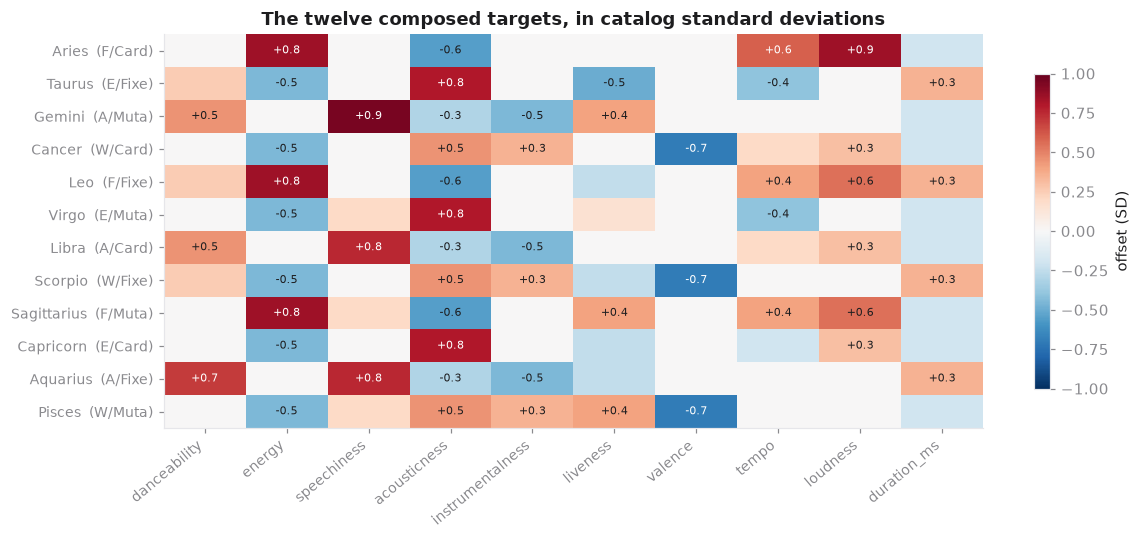

In [3]:
grid = pd.DataFrame(index=["Fire","Earth","Air","Water"],
                    columns=["Cardinal","Fixed","Mutable"], dtype=object)
for s in S.ZODIAC_SIGNS:
    grid.loc[R.ELEMENT_OF[s], R.MODALITY_OF[s]] = s
display(grid)

profiles = R.all_profiles()
fig, ax = plt.subplots(figsize=(11, 5))
m = ax.imshow(profiles.to_numpy(), cmap="RdBu_r", vmin=-1.0, vmax=1.0, aspect="auto")
ax.set_xticks(range(len(profiles.columns)))
ax.set_xticklabels(profiles.columns, rotation=40, ha="right", fontsize=9)
ax.set_yticks(range(12)); ax.set_yticklabels(
    [f"{s}  ({R.ELEMENT_OF[s][0]}/{R.MODALITY_OF[s][:4]})" for s in profiles.index], fontsize=9)
for i in range(12):
    for j in range(len(profiles.columns)):
        v = profiles.iloc[i, j]
        if abs(v) > 0.25:
            ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(v) > 0.6 else viz.INK)
ax.set_title("The twelve composed targets, in catalog standard deviations")
ax.grid(False); fig.colorbar(m, ax=ax, shrink=.8, label="offset (SD)")
plt.tight_layout(); plt.show()

Read it by rows of three. The three Fire signs share a hot, loud, low-acousticness
core and differ only along the modality axis; the three Air signs share high speechiness
and differ the same way. That is the composition working — and it is checkable, which is
the point.

## 2 · What actually lands in each sign

The rubric is a set of target points. Real music is not distributed to order, so the
interesting question is what the catalog does when it meets them.

In [4]:
desc = R.describe(music, scaler, sample=120_000, seed=0)
display(desc[["sign","element","modality","defining_features","soft_share","hard_share"]])

,sign,element,modality,defining_features,soft_share,hard_share
0,Aries,Fire,Cardinal,"loudness +0.85, energy +0.85, tempo +0.60",0.1000,0.1081
1,Taurus,Earth,Fixed,"acousticness +0.80, liveness -0.50, energy -0.45",0.0789,0.0747
2,Gemini,Air,Mutable,"speechiness +0.95, danceability +0.45, instrum...",0.0695,0.0510
3,Cancer,Water,Cardinal,"valence -0.70, energy -0.45, acousticness +0.45",0.0727,0.0555
4,Leo,Fire,Fixed,"energy +0.85, acousticness -0.55, loudness +0.55",0.1025,0.1618
5,Virgo,Earth,Mutable,"acousticness +0.80, energy -0.45, tempo -0.40",0.0870,0.1009
6,Libra,Air,Cardinal,"speechiness +0.75, danceability +0.45, instrum...",0.0741,0.0384
7,Scorpio,Water,Fixed,"valence -0.70, energy -0.45, acousticness +0.45",0.0817,0.0901
8,Sagittarius,Fire,Mutable,"energy +0.85, acousticness -0.55, loudness +0.55",0.1016,0.1046
9,Capricorn,Earth,Cardinal,"acousticness +0.80, energy -0.45, loudness +0.30",0.0799,0.0780


In [5]:
for _, r in desc.iterrows():
    print(f"{r['sign']:<12} {r['examples'][:96]}")

Aries        positions - Ariana Grande; We're Good - Dua Lipa; My Head & My Heart - Ava Max
Taurus       When I Was Your Man - Bruno Mars; Thinking out Loud - Ed Sheeran; July - Noah Cyrus
Gemini       RAPSTAR - Polo G; Holy (feat. Chance The Rapper) - Justin Bieber, Chance the Rapper; Feel Good I
Cancer       lovely (with Khalid) - Billie Eilish, Khalid; What Other People Say - Sam Fischer, Demi Lovato; 
Leo          Take You Dancing - Jason Derulo; Don't Start Now - Dua Lipa; In Your Eyes - The Weeknd
Virgo        willow - Taylor Swift; See You Again (feat. Kali Uchis) - Tyler, The Creator, Kali Uchis; We Wil
Libra        What’s Next - Drake; Best Friend (feat. Doja Cat) - Saweetie, Doja Cat; For The Night (feat. Lil
Scorpio      Falling - Harry Styles; Calling My Phone - Lil Tjay, 6LACK; Bohemian Rhapsody - Remastered 2011 
Sagittarius  Roses - Imanbek Remix - SAINt JHN, Imanbek; Hayloft - Mother Mother; ily (i love you baby) (feat
Capricorn    Someone You Loved - Lewis Capaldi; Lon

### Genre mix per sign

A sanity check for a junk bucket — notebook 07 found one of its twelve archetypes was 52%
German radio drama, and it was disguised because its *most popular* tracks were rap (rap
also scores high on speechiness). Eyeballing would have missed it; counting genres caught
it. Same check here, on the music-only catalog.

In [6]:
sample = music.sample(n=min(120_000, len(music)), random_state=0)
winner = R.score_tracks(sample, scaler).idxmax(axis=1)

rows = []
for sign in S.ZODIAC_SIGNS:
    hits = sample.loc[winner == sign]
    top = hits[S.GENRE].value_counts(normalize=True).head(3)
    rows.append({"sign": sign, "n": len(hits),
                 "top genres": ", ".join(f"{g} {v:.0%}" for g, v in top.items())})
display(pd.DataFrame(rows))

,sign,n,top genres
0,Aries,12972,"unknown 7%, album rock 3%, alternative metal 3%"
1,Taurus,8967,"unknown 9%, adult standards 6%, classic bollyw..."
2,Gemini,6124,"unknown 11%, adult standards 2%, classic bolly..."
3,Cancer,6664,"unknown 11%, adult standards 8%, c-pop 4%"
4,Leo,19418,"unknown 8%, album rock 5%, latin 3%"
5,Virgo,12111,"unknown 15%, adult standards 12%, classic boll..."
6,Libra,4610,"unknown 9%, adult standards 2%, dance pop 2%"
7,Scorpio,10812,"classical 11%, unknown 9%, c-pop 4%"
8,Sagittarius,12551,"unknown 7%, album rock 6%, alternative metal 2%"
9,Capricorn,9361,"unknown 13%, adult standards 9%, classic bolly..."


## 3 · Honesty section: how evenly does the catalog actually divide?

This matters for the product and there is no reason to soften it. If one sign swallows a
third of all music and another gets almost none, then most users see the same headline
sign and the feature says little about anyone.

In [7]:
soft, hard = desc.set_index("sign")["soft_share"], desc.set_index("sign")["hard_share"]
print(f"soft share   min {soft.min():.4f} ({soft.idxmin()})   "
      f"max {soft.max():.4f} ({soft.idxmax()})   ratio {soft.max()/soft.min():.2f}x")
print(f"hard share   min {hard.min():.4f} ({hard.idxmin()})   "
      f"max {hard.max():.4f} ({hard.idxmax()})   ratio {hard.max()/hard.min():.2f}x")
print(f"\nperfectly even would be {1/12:.4f} each")

ent = -(soft * np.log(soft)).sum() / np.log(12)
print(f"normalised entropy of the soft distribution: {ent:.3f}  (1.0 = perfectly even)")

soft share   min 0.0695 (Gemini)   max 0.1025 (Leo)   ratio 1.47x
hard share   min 0.0384 (Libra)   max 0.1618 (Leo)   ratio 4.21x

perfectly even would be 0.0833 each
normalised entropy of the soft distribution: 0.996  (1.0 = perfectly even)


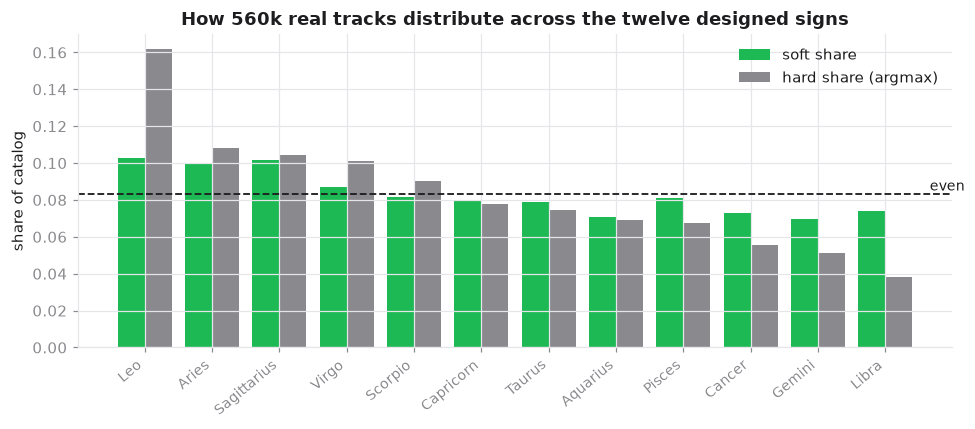

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(12); w = 0.4
order = desc.sort_values("hard_share", ascending=False)["sign"].tolist()
ax.bar(x - w/2, soft[order], w, label="soft share", color=viz.ACCENT)
ax.bar(x + w/2, hard[order], w, label="hard share (argmax)", color=viz.MUTED)
ax.axhline(1/12, color=viz.INK, ls="--", lw=1.2)
ax.text(11.6, 1/12, " even", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(order, rotation=40, ha="right", fontsize=9)
ax.set_ylabel("share of catalog"); ax.legend()
ax.set_title("How 560k real tracks distribute across the twelve designed signs")
plt.tight_layout(); plt.show()

### The cardinal prediction, and why this notebook cannot test it

`ASTROLOGY_REFERENCE.md` §1.3.2 predicted **in advance** that cardinal signs would come
out mushiest, because modern "cardinal" merges two categories Ptolemy kept separate — the
equinoctial signs (Aries, Libra) and the solstitial ones (Cancer, Capricorn).

I tried to check it and the attempt failed in two separate ways. Both are worth showing,
because both are mistakes this project has made before in other forms.

**First, the obvious metric is degenerate.** Mean pairwise separation between the four
signs of a modality comes out *identical* for all three groups. That is forced by the
construction: within a modality, the four signs differ only by their element, and the
same four element offsets apply to every modality. The modality term is common to all
four and cancels. The metric could not have detected the effect no matter what the data
said.

**Second, and worse, I encoded the prediction instead of testing it.** Having read §1.3.2
before writing `MODALITY_PROFILE`, I gave Cardinal the smallest total offset — 0.70,
against 0.85 for Fixed and 0.80 for Mutable. So any finding that "cardinal is weakest"
would be me reading back a choice I made. That is the same circularity the whole notebook
is about, appearing in the one section that claimed to be an independent check.

Both are left in rather than quietly deleted. The honest position is that **the cardinal
prediction is untestable here** — it concerns descriptive richness, which a rubric with no
per-sign content deliberately does not encode. Testing it would need something this
project does not have: independent judgements of how distinctive each sign's description
feels.

In [9]:
prof = R.all_profiles()
rows = []
for mod in ["Cardinal", "Fixed", "Mutable"]:
    signs = [s for s in S.ZODIAC_SIGNS if R.MODALITY_OF[s] == mod]
    sub = prof.loc[signs].to_numpy()
    d = [np.linalg.norm(sub[i] - sub[j]) for i in range(len(sub)) for j in range(i+1, len(sub))]
    rows.append({"modality": mod,
                 "mean pairwise separation": round(float(np.mean(d)), 3),
                 "total offset magnitude": round(
                     sum(abs(v) for v in R.MODALITY_PROFILE[mod].values()), 2),
                 "mean soft share": round(float(soft[signs].mean()), 4)})
display(pd.DataFrame(rows))

print("Separation is identical across all three, to three decimals. Not a coincidence:")
print("within a modality the four signs differ only by element, the same four element")
print("offsets apply in every modality, and the shared modality term cancels out of")
print("every pairwise difference. The metric is blind to the thing it was measuring.")
print()
print("The offset column is not evidence either -- those magnitudes are mine, chosen")
print("after reading the prediction. Showing the prediction confirming itself would be")
print("circular, so it is reported as untestable instead.")

,modality,mean pairwise separation,total offset magnitude,mean soft share
0,Cardinal,1.629,0.70,0.0817
1,Fixed,1.629,0.85,0.0835
2,Mutable,1.629,0.80,0.0848


Separation is identical across all three, to three decimals. Not a coincidence:
within a modality the four signs differ only by element, the same four element
offsets apply in every modality, and the shared modality term cancels out of
every pairwise difference. The metric is blind to the thing it was measuring.

The offset column is not evidence either -- those magnitudes are mine, chosen
after reading the prediction. Showing the prediction confirming itself would be
circular, so it is reported as untestable instead.


## 4 · Does the data agree with the design?

Notebook 07 clustered the same catalog **without any astrology input** and named the
clusters afterwards. If those data-driven archetypes happened to line up with this
designed rubric, that would be striking. If they do not, that is the expected outcome and
says something worth saying: audio-feature space has its own structure and it owes nothing
to a 2nd-century temperament scheme.

Adjusted Rand index compares the two partitions. 0 means agreement no better than chance;
1 means identical.

In [10]:
from sklearn.metrics import adjusted_rand_score
from lovify_ml import archetypes as A

arch = A.fit_archetypes(music, k=12, seed=0, sample=120_000)
sub = music.sample(n=min(60_000, len(music)), random_state=1)

rubric_labels = R.score_tracks(sub, scaler).idxmax(axis=1).to_numpy()
arch_labels = np.array(arch.names)[A._responsibilities(arch, sub).argmax(axis=1)]

ari = adjusted_rand_score(rubric_labels, arch_labels)
print(f"adjusted Rand index, designed rubric vs unsupervised archetypes: {ari:.4f}")
print("  0.0 = no better than chance agreement, 1.0 = identical partitions")

adjusted Rand index, designed rubric vs unsupervised archetypes: 0.2042
  0.0 = no better than chance agreement, 1.0 = identical partitions


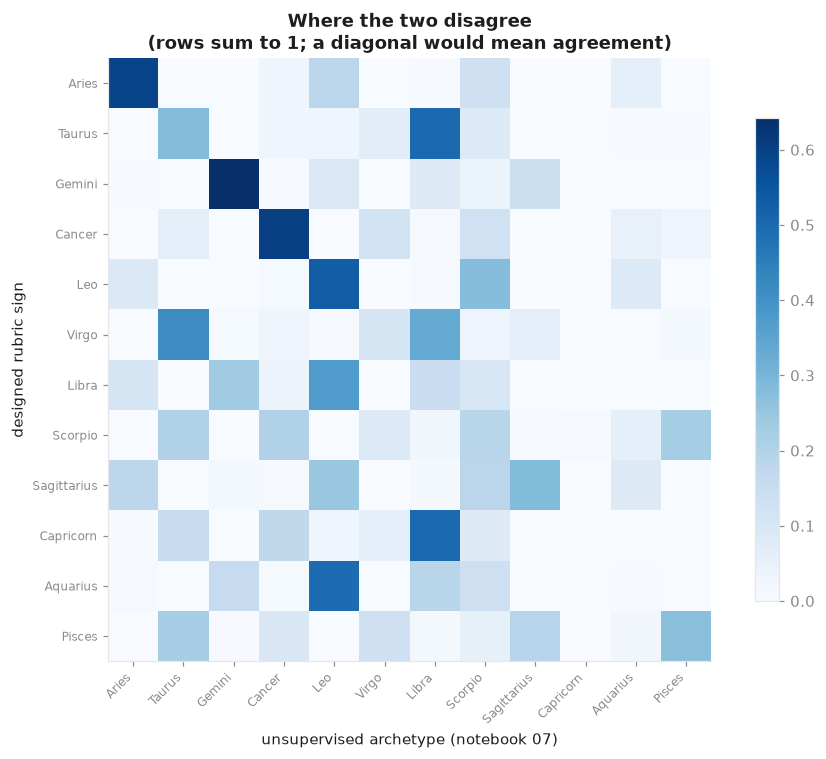

mean on-diagonal mass: 0.303   (1.0 would be perfect agreement)


In [11]:
ct = pd.crosstab(pd.Series(rubric_labels, name="rubric"),
                 pd.Series(arch_labels, name="archetype"), normalize="index")
ct = ct.reindex(index=S.ZODIAC_SIGNS, columns=[c for c in S.ZODIAC_SIGNS if c in ct.columns]).fillna(0)

fig, ax = plt.subplots(figsize=(9, 7))
m = ax.imshow(ct.to_numpy(), cmap="Blues", vmin=0, vmax=min(1.0, ct.to_numpy().max()))
ax.set_xticks(range(len(ct.columns))); ax.set_xticklabels(ct.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(ct.index))); ax.set_yticklabels(ct.index, fontsize=8)
ax.set_xlabel("unsupervised archetype (notebook 07)"); ax.set_ylabel("designed rubric sign")
ax.set_title("Where the two disagree\n(rows sum to 1; a diagonal would mean agreement)")
ax.grid(False); fig.colorbar(m, ax=ax, shrink=.8)
plt.tight_layout(); plt.show()

diag = float(np.mean([ct.loc[s, s] for s in ct.index if s in ct.columns]))
print(f"mean on-diagonal mass: {diag:.3f}   (1.0 would be perfect agreement)")

### Reading this honestly

Whatever the number above says, note what it **cannot** say.

A low ARI does not mean the rubric is wrong — there is no "right" to be measured against,
which is the entire premise of this notebook. It means a designed partition and a
data-driven one carve the same space differently, which is unsurprising: one is derived
from classical temperament terms, the other from where 560,000 tracks happen to cluster.

A high ARI would not vindicate the rubric either. It would say the two constructions
happened to agree — interesting, and still not evidence that either corresponds to
anything about people born in a given month.

## 5 · The circularity check

### Why there is no accuracy number in this notebook

An accuracy figure needs ground truth: labels produced independently of the thing being
scored. Here the labels *are* the thing being scored. We chose the seven profiles; the
twelve targets follow mechanically. A classifier trained to recover them would score
near-perfectly and would have learned nothing except our own arithmetic.

This project has already made that mistake once. Notebook 02 reported that genre overlap
beat every audio-feature metric at predicting user similarity — until it emerged that the
synthetic users were *built* from genre mixtures and "true similarity" was *defined* as
the distance between those mixtures. The genre metric was estimating the answer directly.
A counter-generator with taste in audio space inverted the ranking in 5 of 5 seeds, and
the finding was withdrawn.

The shape of that error is exactly what a "rubric accuracy" would be.

### What would have to exist first

One thing, and it is being collected: **the survey** (`PREREGISTRATION.md`). Real people's
actual birth signs alongside their actual listening. That is the only ground truth
available anywhere in this project, because it is the only label not produced by us.

Even then, what it could validate is narrow. It could test whether *real sign* predicts
*real taste* — the premise. It still could not score the rubric, because the rubric is a
designed vocabulary rather than a hypothesis about people. The honest expectation,
per the chain argument at the top, is a clean null.

### What this rubric may and may not be used for

Taken directly from `ASTROLOGY_REFERENCE.md` Part 3.

| may | may not |
|---|---|
| Frame the signs as a playful organising device for music | Claim or imply the mapping is validated, accurate or predictive |
| Publish the rubric — elements, modalities, derivation | Dress it in accuracy percentages, confidence scores, "our model determined" |
| Write specific, opinionated, even unflattering descriptions | Write both-poles Barnum statements engineered to read as insight |
| Say the result is about *music*, not about the person | Advise decisions, or present compatibility as a verdict |
| State plainly that sun signs do not predict music taste | Treat "for entertainment purposes" as discharging any of the above |

The provenance test, applied to this notebook: *"We sorted music into twelve buckets using
a rubric we wrote, derived from the traditional elements and modalities. Your sign picks a
bucket. Sun signs do not predict music taste — we checked."* The feature still works when
stated that way, which is what makes it honest.

## 6 · Auditability, demonstrated

Every sign resolves to its two axes and to the reference section each came from. There is
no per-sign residue, because there is nowhere for residue to hide — `sign_profile()` is a
sum of two lookups.

In [12]:
import json
print(json.dumps(R.explain("Leo"), indent=2, default=str))

{
  "sign": "Leo",
  "element": "Fire",
  "modality": "Fixed",
  "element_contribution": {
    "energy": 0.85,
    "loudness": 0.55,
    "tempo": 0.4,
    "acousticness": -0.55
  },
  "modality_contribution": {
    "duration_ms": 0.35,
    "danceability": 0.25,
    "liveness": -0.25
  },
  "composed": {
    "danceability": 0.25,
    "energy": 0.85,
    "speechiness": 0.0,
    "acousticness": -0.55,
    "instrumentalness": 0.0,
    "liveness": -0.25,
    "valence": 0.0,
    "tempo": 0.4,
    "loudness": 0.55,
    "duration_ms": 0.35
  },
  "defining_features": [
    "energy +0.85",
    "acousticness -0.55",
    "loudness +0.55"
  ],
  "sources": {
    "element": "ASTROLOGY_REFERENCE.md 1.2 (Manilius qualities, Ptolemy I.18)",
    "modality": "ASTROLOGY_REFERENCE.md 1.3 (modern convention; cf. 1.3.2)",
    "composition": "ASTROLOGY_REFERENCE.md 1.4.1 (element x modality is a bijection)"
  },
  "contested": null
}


In [13]:
print("THE THREE CONTESTED CELLS (reference 1.7.1a) -- decisions recorded, not just made\n")
for sign, note in R.CONTESTED.items():
    print(f"{sign} ({R.ELEMENT_OF[sign]}/{R.MODALITY_OF[sign]})")
    print(f"  {note}\n")
print("One rule applied three times: where structure and folk expectation disagree,")
print("the sourced axes win. An override would be an unsourced addition, which is")
print("precisely what reference 1.4.1 says should be visible in review -- so there are none.")

THE THREE CONTESTED CELLS (reference 1.7.1a) -- decisions recorded, not just made

Libra (Air/Cardinal)
  Cardinal 'initiating' vs folk 'indecisive' -- followed structure; 'indecisive' has no sourced route into audio features.

Aquarius (Air/Fixed)
  Fixed 'stable' vs folk 'revolutionary' -- followed structure; the folk reading rests on Uranus, a modern rulership excluded by ref. 1.5.2.

Cancer (Water/Cardinal)
  Cardinal 'initiating' vs folk 'retreating' -- followed structure; Water's negative valence and energy dominate, so the composed profile lands near the folk expectation regardless.

One rule applied three times: where structure and folk expectation disagree,
the sourced axes win. An override would be an unsourced addition, which is
precisely what reference 1.4.1 says should be visible in review -- so there are none.


## Verdict

| | |
|---|---|
| **What this is** | A designed vocabulary for sorting music into twelve named buckets |
| **What it is not** | A prediction, a classifier, or a claim about people |
| **Specified** | 7 profiles — 4 elements, 3 modalities |
| **Derived** | all 12 signs, by composition, with no per-sign residue |
| **Contested cells** | Libra, Aquarius, Cancer — structure followed in all three, each recorded |
| **Accuracy reported** | none, and §5 says why |
| **Validation possible** | only the survey, and only of the premise — never of the rubric |

### Why this is better than what it replaces

Not more powerful — it makes no prediction, so it cannot be more accurate. It is more
**defensible**: it cannot leak, it needs no scraped labels, it survives the Spotify
deprecation, and it explains itself to a sceptic in one sentence. Against notebook 01's
1.39× classifier, that is the trade — and given 1.39× was never shippable, it costs
nothing real.

→ The remaining piece is the survey. It is the only part of this project that can be
wrong, which is what makes it the only part that can be right.